#### Load Packages

In [ ]:
suppressMessages(library(tidyverse))
suppressMessages(library(forcats))
suppressMessages(library(pheatmap))
suppressMessages(library(RColorBrewer))

source("./Manuscript_files/theme_ggplot_cfrna.R")

#### Plotting Code

In [111]:
ipa_data <- read.delim("./Manuscript_files/ipa_data_output.tsv", sep = "\t", header = TRUE)
head(ipa_data, 3)

,Ingenuity_Canonical_Pathways,Neg_log_pvalue,Ratio,z_score,Molecules
,<chr>,<dbl>,<dbl>,<dbl>,<chr>
1,FAK Signaling,6.17,0.0434,5.126,"ADRB1,CAPN10,CCR7,CELSR1,CNR2,COL1A1,FLT4,GABBR1,GPR35,IFNLR1,IL10RA,IL11RA,IL12RB2,IL18R1,IL18RAP,IL4R,ITGA10,ITGB7,LPAR1,LTB4R,MMP2,OPRL1,P2RY2,TGFB2,TRAJ1,TRAJ10,TRAJ12,TRAJ14,TRAJ16,TRAJ18,TRAJ19,TRAJ20,TRAJ23,TRAJ26,TRAJ29,TRAJ33,TRAJ37,TRAJ46,TRAJ6,TRAJ7,TRAV21,TRBJ1-3,TRBJ2-6,TRBJ2-7,VIPR1"
2,IL-4 Signaling,4.92,0.0487,4.158,"COL1A1,COL4A3,COL4A4,COL5A3,COL9A2,IGHE,IL4R,TGFB2,TRAJ1,TRAJ10,TRAJ12,TRAJ14,TRAJ16,TRAJ18,TRAJ19,TRAJ20,TRAJ23,TRAJ26,TRAJ29,TRAJ33,TRAJ37,TRAJ46,TRAJ6,TRAJ7,TRAV21,TRBJ1-3,TRBJ2-6,TRBJ2-7"
3,STAT3 Pathway,4.69,0.0863,1.890,"BMPR1A,FGFR1,FLT4,IFNLR1,IGF2R,IL10RA,IL11RA,IL12RB2,IL18R1,IL18RAP,IL4R,TGFB2"


In [112]:
# Select the top 8 pathways by Neg_log_pvalue
plot_pathways <- ipa_data %>%
  arrange(desc(Neg_log_pvalue)) %>%
  filter(!is.na(z_score)) %>%
  mutate(z_score = as.numeric(z_score)) %>%
  filter(abs(z_score) > 0.5) %>% 
  slice_head(n = 10)

# Add a pathway
additional_pathway <- ipa_data %>%
  filter(Ingenuity_Canonical_Pathways == "CTLA4 Signaling in Cytotoxic T Lymphocytes") %>%
  mutate(z_score = as.numeric(z_score))

plot_pathways <- bind_rows(plot_pathways, additional_pathway) %>%
  distinct() 

plot_pathways

Ingenuity_Canonical_Pathways,Neg_log_pvalue,Ratio,z_score,Molecules
<chr>,<dbl>,<dbl>,<dbl>,<chr>
FAK Signaling,6.17,0.0434,5.126,"ADRB1,CAPN10,CCR7,CELSR1,CNR2,COL1A1,FLT4,GABBR1,GPR35,IFNLR1,IL10RA,IL11RA,IL12RB2,IL18R1,IL18RAP,IL4R,ITGA10,ITGB7,LPAR1,LTB4R,MMP2,OPRL1,P2RY2,TGFB2,TRAJ1,TRAJ10,TRAJ12,TRAJ14,TRAJ16,TRAJ18,TRAJ19,TRAJ20,TRAJ23,TRAJ26,TRAJ29,TRAJ33,TRAJ37,TRAJ46,TRAJ6,TRAJ7,TRAV21,TRBJ1-3,TRBJ2-6,TRBJ2-7,VIPR1"
IL-4 Signaling,4.92,0.0487,4.158,"COL1A1,COL4A3,COL4A4,COL5A3,COL9A2,IGHE,IL4R,TGFB2,TRAJ1,TRAJ10,TRAJ12,TRAJ14,TRAJ16,TRAJ18,TRAJ19,TRAJ20,TRAJ23,TRAJ26,TRAJ29,TRAJ33,TRAJ37,TRAJ46,TRAJ6,TRAJ7,TRAV21,TRBJ1-3,TRBJ2-6,TRBJ2-7"
STAT3 Pathway,4.69,0.0863,1.890,"BMPR1A,FGFR1,FLT4,IFNLR1,IGF2R,IL10RA,IL11RA,IL12RB2,IL18R1,IL18RAP,IL4R,TGFB2"
NCAM signaling for neurite out-growth,4.50,0.1270,2.828,"CACNA1I,COL4A3,COL4A4,COL5A3,COL9A2,FGFR1,NCAM1,SPTBN2"
Dendritic Cell Maturation,4.50,0.0461,1.633,"CCR7,CD1D,COL1A1,COL5A3,FCGR2B,FSCN2,LY75,PLCH2,TRAJ1,TRAJ10,TRAJ12,TRAJ14,TRAJ16,TRAJ18,TRAJ19,TRAJ20,TRAJ23,TRAJ26,TRAJ29,TRAJ33,TRAJ37,TRAJ46,TRAJ6,TRAJ7,TRAV21,TRBJ1-3,TRBJ2-6,TRBJ2-7"
T Cell Exhaustion Signaling Pathway,4.17,0.0459,2.449,"IFNAR2,IL10RA,IL12RB2,IRF9,LAG3,PPM1J,TRAJ1,TRAJ10,TRAJ12,TRAJ14,TRAJ16,TRAJ18,TRAJ19,TRAJ20,TRAJ23,TRAJ26,TRAJ29,TRAJ33,TRAJ37,TRAJ46,TRAJ6,TRAJ7,TRAV21,TRBJ1-3,TRBJ2-6,TRBJ2-7"
Lipid Antigen Presentation by CD1,4.08,0.0507,4.472,"CD1D,TRAJ1,TRAJ10,TRAJ12,TRAJ14,TRAJ16,TRAJ18,TRAJ19,TRAJ20,TRAJ23,TRAJ26,TRAJ29,TRAJ33,TRAJ37,TRAJ46,TRAJ6,TRAJ7,TRAV21,TRBJ1-3,TRBJ2-6,TRBJ2-7"
NFKBIE Signaling Pathway,3.60,0.0468,4.583,"TNFSF15,TRAJ1,TRAJ10,TRAJ12,TRAJ14,TRAJ16,TRAJ18,TRAJ19,TRAJ20,TRAJ23,TRAJ26,TRAJ29,TRAJ33,TRAJ37,TRAJ46,TRAJ6,TRAJ7,TRAV21,TRBJ1-3,TRBJ2-6,TRBJ2-7"
Collagen degradation,3.59,0.1090,1.134,"COL1A1,COL4A3,COL4A4,COL5A3,COL9A2,MMP11,MMP2"


In [113]:
# Organize pathway names 
plot_pathways_mod <- plot_pathways %>%
    mutate(Ingenuity_Canonical_Pathways = recode(Ingenuity_Canonical_Pathways,
        "STAT3 Pathway" = "STAT3",
        "NCAM signaling for neurite out-growth" = "NCAM Signaling",
        "T Cell Exhaustion Signaling Pathway" = "T Cell Exhaustion Signaling",
        "NFKBIE Signaling Pathway" = "NFKBIE Signaling",
        "Collagen degradation" = "Collagen Degradation",
        "Extracellular matrix organization" = "Extracellular Matrix Organization",
        "CTLA4 Signaling in Cytotoxic T Lymphocytes" = "CTLA4 Signaling in Cytotoxic T cells"
    ))

# Check the updated pathway names
plot_pathways_mod

Ingenuity_Canonical_Pathways,Neg_log_pvalue,Ratio,z_score,Molecules
<chr>,<dbl>,<dbl>,<dbl>,<chr>
FAK Signaling,6.17,0.0434,5.126,"ADRB1,CAPN10,CCR7,CELSR1,CNR2,COL1A1,FLT4,GABBR1,GPR35,IFNLR1,IL10RA,IL11RA,IL12RB2,IL18R1,IL18RAP,IL4R,ITGA10,ITGB7,LPAR1,LTB4R,MMP2,OPRL1,P2RY2,TGFB2,TRAJ1,TRAJ10,TRAJ12,TRAJ14,TRAJ16,TRAJ18,TRAJ19,TRAJ20,TRAJ23,TRAJ26,TRAJ29,TRAJ33,TRAJ37,TRAJ46,TRAJ6,TRAJ7,TRAV21,TRBJ1-3,TRBJ2-6,TRBJ2-7,VIPR1"
IL-4 Signaling,4.92,0.0487,4.158,"COL1A1,COL4A3,COL4A4,COL5A3,COL9A2,IGHE,IL4R,TGFB2,TRAJ1,TRAJ10,TRAJ12,TRAJ14,TRAJ16,TRAJ18,TRAJ19,TRAJ20,TRAJ23,TRAJ26,TRAJ29,TRAJ33,TRAJ37,TRAJ46,TRAJ6,TRAJ7,TRAV21,TRBJ1-3,TRBJ2-6,TRBJ2-7"
STAT3,4.69,0.0863,1.890,"BMPR1A,FGFR1,FLT4,IFNLR1,IGF2R,IL10RA,IL11RA,IL12RB2,IL18R1,IL18RAP,IL4R,TGFB2"
NCAM Signaling,4.50,0.1270,2.828,"CACNA1I,COL4A3,COL4A4,COL5A3,COL9A2,FGFR1,NCAM1,SPTBN2"
Dendritic Cell Maturation,4.50,0.0461,1.633,"CCR7,CD1D,COL1A1,COL5A3,FCGR2B,FSCN2,LY75,PLCH2,TRAJ1,TRAJ10,TRAJ12,TRAJ14,TRAJ16,TRAJ18,TRAJ19,TRAJ20,TRAJ23,TRAJ26,TRAJ29,TRAJ33,TRAJ37,TRAJ46,TRAJ6,TRAJ7,TRAV21,TRBJ1-3,TRBJ2-6,TRBJ2-7"
T Cell Exhaustion Signaling,4.17,0.0459,2.449,"IFNAR2,IL10RA,IL12RB2,IRF9,LAG3,PPM1J,TRAJ1,TRAJ10,TRAJ12,TRAJ14,TRAJ16,TRAJ18,TRAJ19,TRAJ20,TRAJ23,TRAJ26,TRAJ29,TRAJ33,TRAJ37,TRAJ46,TRAJ6,TRAJ7,TRAV21,TRBJ1-3,TRBJ2-6,TRBJ2-7"
Lipid Antigen Presentation by CD1,4.08,0.0507,4.472,"CD1D,TRAJ1,TRAJ10,TRAJ12,TRAJ14,TRAJ16,TRAJ18,TRAJ19,TRAJ20,TRAJ23,TRAJ26,TRAJ29,TRAJ33,TRAJ37,TRAJ46,TRAJ6,TRAJ7,TRAV21,TRBJ1-3,TRBJ2-6,TRBJ2-7"
NFKBIE Signaling,3.60,0.0468,4.583,"TNFSF15,TRAJ1,TRAJ10,TRAJ12,TRAJ14,TRAJ16,TRAJ18,TRAJ19,TRAJ20,TRAJ23,TRAJ26,TRAJ29,TRAJ33,TRAJ37,TRAJ46,TRAJ6,TRAJ7,TRAV21,TRBJ1-3,TRBJ2-6,TRBJ2-7"
Collagen Degradation,3.59,0.1090,1.134,"COL1A1,COL4A3,COL4A4,COL5A3,COL9A2,MMP11,MMP2"


In [114]:
plot_pathways_mod <- plot_pathways_mod %>%
  arrange(desc(z_score)) %>% # Sort by descending Z-score, then NaN at the bottom
  mutate(Pathway = factor(Ingenuity_Canonical_Pathways, levels = Ingenuity_Canonical_Pathways))  # Ensure factor levels match sorted order

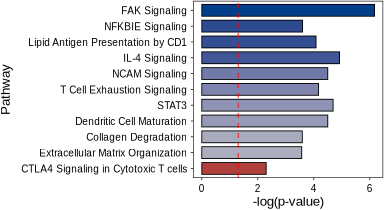

In [115]:
# TOP 10 PATHWAYS
width = 3.2
height = 1.75
options(repr.plot.width = width, repr.plot.height = height)

plot_name <- "IPA_res_pathways_new"

plot_me <- ggplot(plot_pathways_mod, aes(x = Neg_log_pvalue, y = fct_rev(Pathway), fill = z_score)) + 
  geom_bar(stat = "identity", colour = "black", width = 0.75, lwd = 0.25) +  
  scale_fill_gradient2(
    high = "#023E8A", mid = "gray80", low = "#a31621", midpoint = 0, 
    name = "z-score") +
  theme_cfrna_paper() +
  geom_vline(xintercept = 1.3, linetype = "dashed", color = "red", lwd = 0.25) +  # Threshold line
  labs(title = NULL, x = "-log(p-value)", y = "Pathway\n") +
  theme(legend.position = "none")

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_4/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

In [116]:
# READ IN FILES
res <- read.csv("./Manuscript_files/deseq2_res.csv", row.names = 1)
counts_vst <- read.csv("./Manuscript_files/counts_vst_output.csv", row.names = 1)
samples <- read.delim("./Manuscript_files/sample_metadata.tsv")
gene.list <- read.delim("./Manuscript_files/gencode.biotype.name.key.tsv")

In [ ]:
# Create a lookup table for gene name to Ensembl ID
gene_lookup <- setNames(gene.list$gene_id, gene.list$gene_name)

# Replace gene names with Ensembl IDs in ipa_data
ipa_data$Molecules <- sapply(ipa_data$Molecules, function(genes) {
  gene_names <- strsplit(genes, ",")[[1]] # Split the string of genes
  ensembl_ids <- gene_lookup[gene_names]  # Look up Ensembl IDs
  paste(ensembl_ids, collapse = ",")  # Rejoin Ensembl IDs into a string
})

In [118]:
# Split the Molecules column into a list of individual genes
ipa_data <- ipa_data[ ,-6]

ipa_genes <- ipa_data %>%
  pull(Molecules) %>%
  str_split(",") %>%
  unlist() %>%
  unique()
  
head(ipa_data)

,Ingenuity_Canonical_Pathways,Neg_log_pvalue,Ratio,z_score,Molecules
,<chr>,<dbl>,<dbl>,<dbl>,<chr>
1,FAK Signaling,6.17,0.0434,5.126,"ENSG00000043591.6,ENSG00000142330.20,ENSG00000126353.3,ENSG00000075275.18,ENSG00000188822.8,ENSG00000108821.14,ENSG00000037280.16,ENSG00000204681.11,ENSG00000178623.12,ENSG00000185436.12,ENSG00000110324.11,ENSG00000137070.18,ENSG00000081985.13,ENSG00000115604.12,ENSG00000115607.9,ENSG00000077238.14,ENSG00000143127.13,ENSG00000139626.16,ENSG00000198121.14,ENSG00000213903.9,ENSG00000087245.13,ENSG00000125510.18,ENSG00000175591.12,ENSG00000092969.12,ENSG00000211888.2,ENSG00000211879.1,ENSG00000211877.1,ENSG00000211875.1,ENSG00000211873.1,ENSG00000211871.1,ENSG00000211870.1,ENSG00000211869.1,ENSG00000211866.1,ENSG00000211863.1,ENSG00000211860.1,ENSG00000211856.1,ENSG00000278661.1,ENSG00000211843.1,ENSG00000211883.1,ENSG00000211882.1,ENSG00000211801.3,ENSG00000282133.1,ENSG00000211770.1,ENSG00000211771.1,ENSG00000114812.13"
2,IL-4 Signaling,4.92,0.0487,4.158,"ENSG00000108821.14,ENSG00000169031.21,ENSG00000081052.14,ENSG00000080573.7,ENSG00000049089.15,ENSG00000211891.6,ENSG00000077238.14,ENSG00000092969.12,ENSG00000211888.2,ENSG00000211879.1,ENSG00000211877.1,ENSG00000211875.1,ENSG00000211873.1,ENSG00000211871.1,ENSG00000211870.1,ENSG00000211869.1,ENSG00000211866.1,ENSG00000211863.1,ENSG00000211860.1,ENSG00000211856.1,ENSG00000278661.1,ENSG00000211843.1,ENSG00000211883.1,ENSG00000211882.1,ENSG00000211801.3,ENSG00000282133.1,ENSG00000211770.1,ENSG00000211771.1"
3,STAT3 Pathway,4.69,0.0863,1.890,"ENSG00000107779.14,ENSG00000077782.22,ENSG00000037280.16,ENSG00000185436.12,ENSG00000197081.16,ENSG00000110324.11,ENSG00000137070.18,ENSG00000081985.13,ENSG00000115604.12,ENSG00000115607.9,ENSG00000077238.14,ENSG00000092969.12"
4,T Helper Cell Differentiation,4.57,0.0506,NA,"ENSG00000110324.11,ENSG00000081985.13,ENSG00000115604.12,ENSG00000077238.14,ENSG00000211888.2,ENSG00000211879.1,ENSG00000211877.1,ENSG00000211875.1,ENSG00000211873.1,ENSG00000211871.1,ENSG00000211870.1,ENSG00000211869.1,ENSG00000211866.1,ENSG00000211863.1,ENSG00000211860.1,ENSG00000211856.1,ENSG00000278661.1,ENSG00000211843.1,ENSG00000211883.1,ENSG00000211882.1,ENSG00000211801.3,ENSG00000282133.1,ENSG00000211770.1,ENSG00000211771.1"
5,Hepatic Fibrosis / Hepatic Stellate Cell Activation,4.54,0.0729,NA,"ENSG00000126353.3,ENSG00000108821.14,ENSG00000169031.21,ENSG00000081052.14,ENSG00000080573.7,ENSG00000049089.15,ENSG00000077782.22,ENSG00000037280.16,ENSG00000159110.21,ENSG00000110324.11,ENSG00000115607.9,ENSG00000077238.14,ENSG00000087245.13,ENSG00000092969.12"
6,NCAM signaling for neurite out-growth,4.50,0.1270,2.828,"ENSG00000100346.18,ENSG00000169031.21,ENSG00000081052.14,ENSG00000080573.7,ENSG00000049089.15,ENSG00000077782.22,ENSG00000149294.17,ENSG00000173898.15"


In [119]:
# Define top pathways
pathways_of_interest <- c("FAK Signaling", "IL-4 Signaling", "STAT3 Pathway", "NCAM signaling for neurite out-growth", 
        "Dendritic Cell Maturation", "T Cell Exhaustion Signaling Pathway", "Lipid Antigen Presentation by CD1", 
        "NFKBIE Signaling Pathway", "Collagen degradation", "Extracellular matrix organization", 
        "CTLA4 Signaling in Cytotoxic T Lymphocytes")

# Filter ipa_data to include only the pathways of interest
subset_ipa_data <- ipa_data[ipa_data$Ingenuity_Canonical_Pathways %in% pathways_of_interest, -6]

# Extract the list of unique genes from the "Molecules" column
genes_of_interest <- unique(unlist(strsplit(subset_ipa_data$Molecules, ",")))

# Subset counts_vst to include only the genes of interest
counts_vst_subset <- counts_vst[rownames(counts_vst) %in% genes_of_interest, ] %>%
        as.data.frame() %>%
        rownames_to_column(var = "gene_id")

In [120]:
# Merge with gene.list to get gene_name
counts_vst_subset_simple <- counts_vst_subset %>%
  left_join(gene.list, by = "gene_id") %>% 
  column_to_rownames(var = "gene_name") %>%  # Replace rownames with gene_name
  select(-gene_id, -gene_type) %>%
  as.matrix()

head(counts_vst_subset_simple, 2)
ncol(counts_vst_subset_simple)

,cfs_cfrna_001,cfs_cfrna_002,cfs_cfrna_003,cfs_cfrna_004,cfs_cfrna_005,cfs_cfrna_006,cfs_cfrna_007,cfs_cfrna_008,cfs_cfrna_011,cfs_cfrna_012,⋯,cfs_cfrna_259,cfs_cfrna_260,cfs_cfrna_264,cfs_cfrna_265,cfs_cfrna_266,cfs_cfrna_267,cfs_cfrna_268,cfs_cfrna_270,cfs_cfrna_271,cfs_cfrna_272
FLT4,4.412405,4.676412,5.267803,4.727197,4.150773,4.589116,3.966767,4.688014,4.596132,5.038601,⋯,4.849010,5.063879,4.810521,5.085853,5.076372,4.234514,4.677963,4.74289,4.608733,4.252286
ADRB1,3.410941,3.977467,3.939222,4.727197,3.410941,3.837604,3.410941,3.848982,4.172892,3.410941,⋯,3.937755,3.410941,4.056292,3.410941,4.534190,3.410941,4.157824,3.99527,3.410941,4.434439


[1] 168

In [121]:
# Define the phenotype colors
phenotype_colors <- c("MECFS" = "#023E8A", "HC" = "#a31621")
sex_colors <- c("F" = "#ea9ab2", "M" = "#1b9aaa")
site_colors = c("ITH" = '#8cb369', "NYC" = '#7678ed', "LA" = '#f7b801')

# Load metadata to associate sample IDs with phenotypes
annotation <- samples[, c("sample_id_0", "phenotype", "sex", "test_site")]
rownames(annotation) <- annotation$sample_id_0
annotation <- annotation[, c("phenotype", "sex", "test_site"), drop = FALSE]

# Add phenotype color annotation
annotation_colors <- list(phenotype = phenotype_colors, sex = sex_colors, 
                          test_site = site_colors)


png 
  2

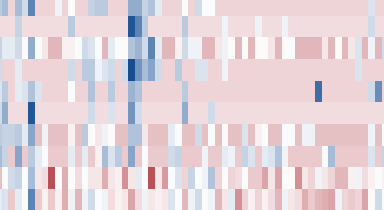

In [122]:
# HEATMAP TOP GENES
plot_name = "IPA_heatmap"

heatmap_width <- 13    
heatmap_height <- 17      

# Generate the heatmap
plot_me <- pheatmap(
  counts_vst_subset_simple,
  scale = "row",
  breaks = seq(-4, 4, length = 51),
  clustering_distance_rows = "correlation", 
  clustering_distance_cols = "correlation",
  show_rownames = FALSE,       
  show_colnames = FALSE,       
  annotation_col = annotation, 
  annotation_colors = annotation_colors, 
  color = colorRampPalette(c("#a31621","white","#023E8A"))(50),                   
  cellwidth = 4,      
  cellheight = 13,    
  border_color = NA,
  annotation_legend = FALSE,
  treeheight_row = 0
)

plot_me

# Save the plot as a PDF
pdf(paste0("/workdir/aeg267/ME_CFS/02_Scripts/Figure_outputs/figure_4/", plot_name, ".pdf"), 
    width = heatmap_width, height = heatmap_height)

print(plot_me)
dev.off()

In [123]:
# FILTER GENE COUNTS FOR MARKER GENES
gene_names <- c('IL18R1', 'TNFSF15', 'ITGA10','IL18RAP','PLCH2', 'LAMA5', 'ADAM12',
               'TGFB2','NCAM1','FGFR1','IFNLR1','CELSR1','MMP2','COL9A2','SPTBN2',
               'TRAJ20','TRAJ16', 'TRBJ2-7','TRAJ19','TRAJ12')

# Get the gene IDs for the specified genes
gene_ids <- gene.list %>% filter(gene_name %in% gene_names) %>% pull(gene_id)

# Get the normalized counts from counts_vst
gene_counts_vst <- counts_vst[gene_ids, ]

gene_counts_vst_ordered <- gene_counts_vst[, samples$sample_id_0]

transposed_counts <- t(gene_counts_vst_ordered)

# Combine with sample metadata
mdf_vst <- cbind(
  samples %>% select(sample_id_0, phenotype, sex, test_site, pre_post_cpet, project),
  transposed_counts
)

# Reshape the data frame for plotting
mdf_vst_long <- mdf_vst %>%
  pivot_longer(cols = starts_with("ENSG"), names_to = "gene_id", values_to = "gene_count") %>%
  left_join(gene.list, by = c("gene_id" = "gene_id"))

# Set the order of genes (IF COMMENTED OUT IT WILL BE ALPHABETICAL)
mdf_vst_long$gene_name <- factor(mdf_vst_long$gene_name, levels = gene_names)

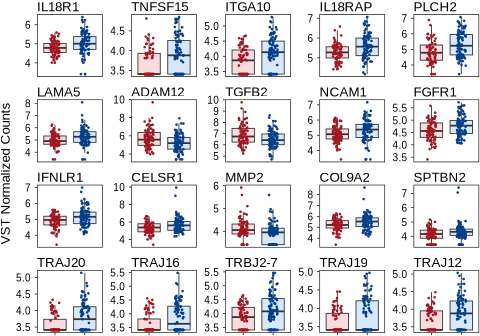

In [124]:
# VST NORMALIZED COUNTS FOR TOP GENES
plot_name = "TOP_genes_new"

width =  4
height = 2.8
options(repr.plot.width = width, repr.plot.height = height)


plot_me <- ggplot(mdf_vst_long, aes(x = phenotype, y = gene_count, fill = phenotype)) +
  geom_boxplot(width = 0.75, outlier.shape = NA, lwd = 0.25) + 
  geom_jitter(aes(color = phenotype), position = position_jitterdodge(jitter.width = 0.3), alpha = 1, size = 0.1) +
  theme_cfrna_paper() +
  scale_fill_manual(values = COLORS_FILL) +
  scale_color_manual(values = COLORS) +
  scale_x_discrete(labels = c("HC" = NULL, "MECFS" = NULL)) +
  facet_wrap(~ gene_name, scales = "free_y", nrow = 4) +
  theme(strip.background = element_blank(), strip.text = element_text(hjust = 0, margin = margin(b = 1))) +
  labs(title = NULL, x = NULL, y = "VST Normalized Counts")

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_4/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)